In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv('D:\R&D\Linear Regression\Advertising (1).csv')

In [3]:
df.head()

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [4]:
df.shape

(200, 5)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   radio       200 non-null    float64
 3   newspaper   200 non-null    float64
 4   sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [6]:
df.describe()

,Unnamed: 0,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


<Axes: xlabel='sales', ylabel='Count'>

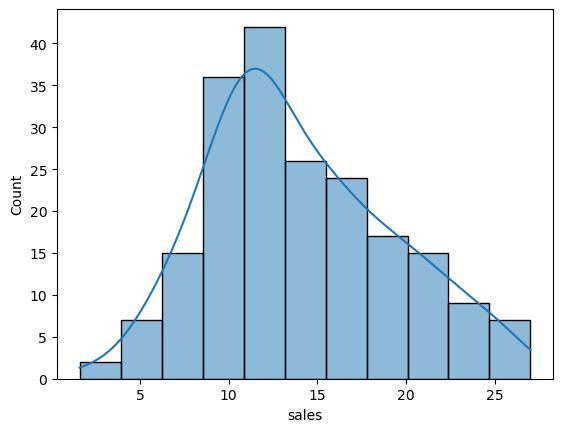

In [7]:
sns.histplot(data=df, x='sales', kde=True)

<Axes: xlabel='TV', ylabel='sales'>

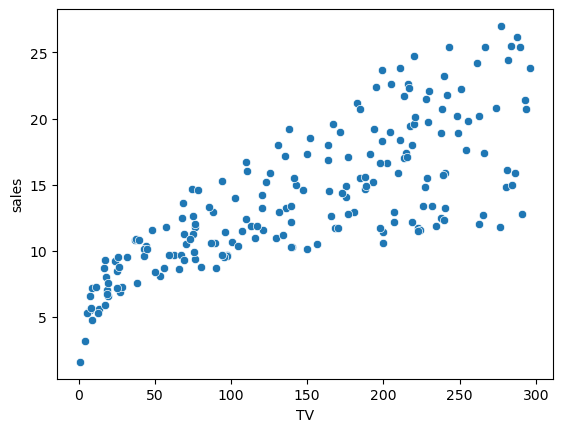

In [8]:
sns.scatterplot(data=df, x='TV', y='sales')

<Axes: xlabel='TV', ylabel='sales'>

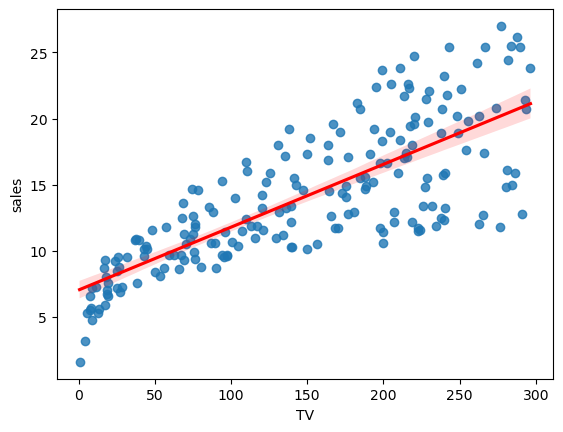

In [9]:
sns.regplot(data=df, x='TV', y='sales', line_kws={'color':'red'})

<Axes: >

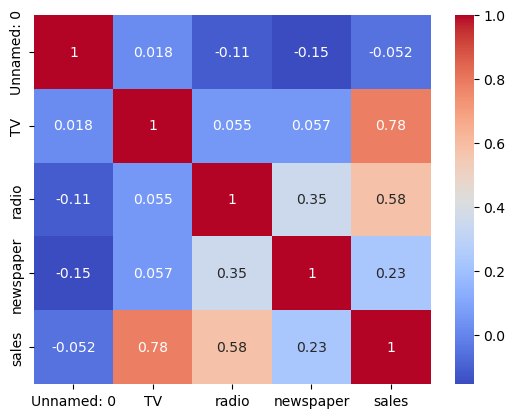

In [10]:
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')


In [11]:
df.isna().sum()

Unnamed: 0    0
TV            0
radio         0
newspaper     0
sales         0
dtype: int64

In [12]:
df=df.drop('Unnamed: 0',axis=1)

In [13]:
df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


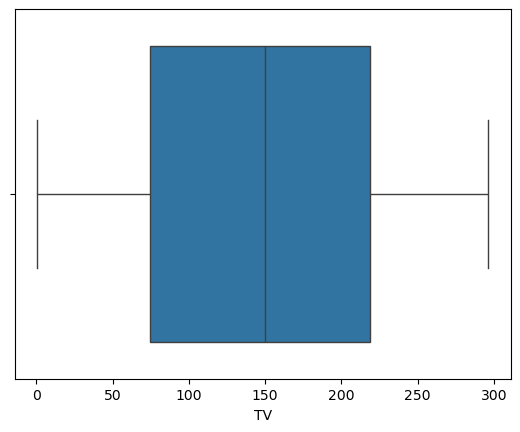

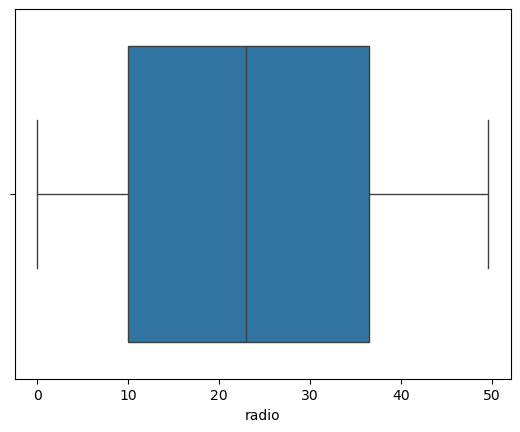

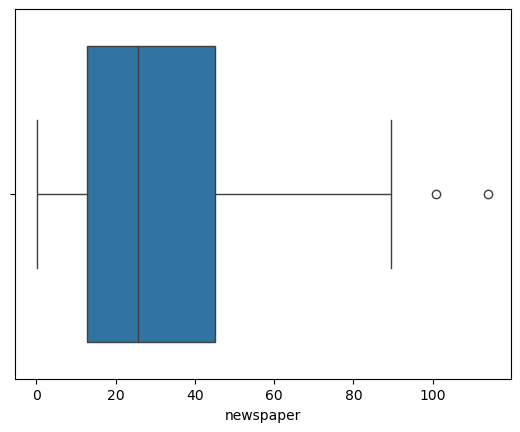

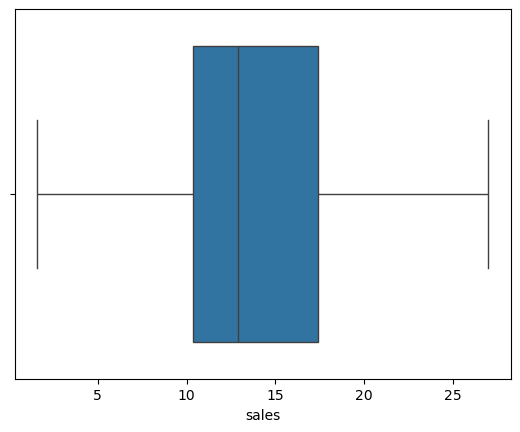

In [14]:
for col in df.columns:
    sns.boxplot(data=df, x=col)
    plt.show()


In [15]:
Q1 = df['newspaper'].quantile(0.25)
Q3 = df['newspaper'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df = df[
    (df['newspaper'] >= lower_bound) &
    (df['newspaper'] <= upper_bound)
]

In [16]:
sim_x=df[['TV']]
y=df['sales']
sim_x_train, sim_x_test, y_train, y_test = train_test_split(sim_x, y, test_size=0.2, random_state=42)

In [17]:
lr = LinearRegression()
lr.fit(sim_x_train, y_train)
y_pred = lr.predict(sim_x_test)

In [18]:
print("Intercept:", lr.intercept_)
print("Coefficient:", lr.coef_)

Intercept: 7.076300057666008
Coefficient: [0.04691212]


Text(0.5, 1.0, 'Actual vs Predicted Values')

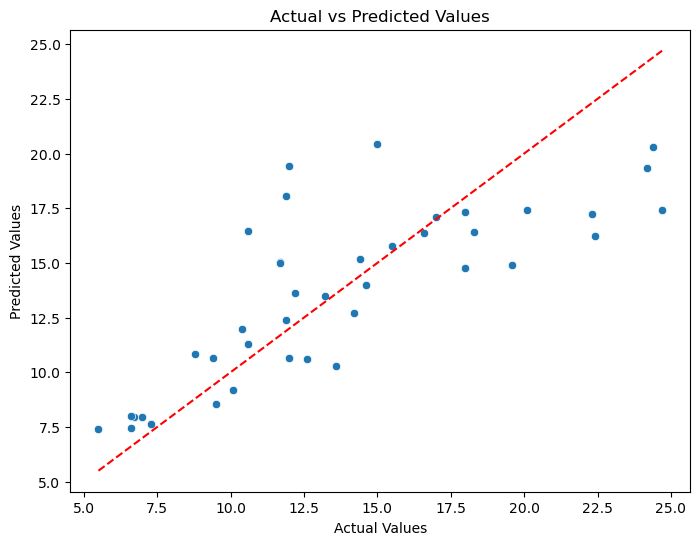

In [19]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Values")


In [20]:
sim_x_accuracy = r2_score(y_test, y_pred)
print("R-squared (Simple Linear Regression):", sim_x_accuracy)


R-squared (Simple Linear Regression): 0.6115685333785085


In [21]:
mul_x = df.drop('sales', axis=1)
mul_x_train, mul_x_test, y_train, y_test = train_test_split(mul_x, y, test_size=0.2, random_state=42)

In [22]:
lr.fit(mul_x_train, y_train)
y_pred_multi = lr.predict(mul_x_test)
print("Intercept:", lr.intercept_)
print("Coefficients:", lr.coef_)

Intercept: 2.979897828416906
Coefficients: [0.04522886 0.18239275 0.00504291]


Text(0.5, 1.0, 'Actual vs Predicted Values (Multiple Linear Regression)')

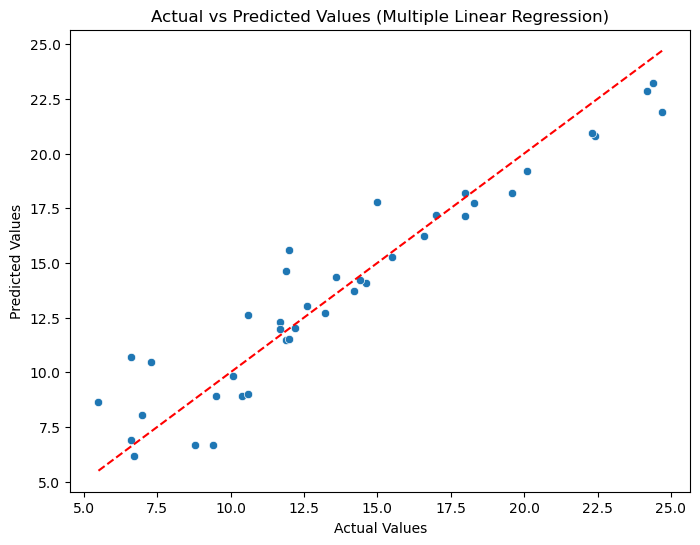

In [23]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred_multi)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Values") 
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Values (Multiple Linear Regression)")


In [24]:
mul_x_accuracy = r2_score(y_test, y_pred_multi)
print("R-squared (Multiple Linear Regression):", mul_x_accuracy)

R-squared (Multiple Linear Regression): 0.8989454779619588
